In [1]:
# imports
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import precision_recall_curve
from sklearn.model_selection import StratifiedGroupKFold, cross_validate, learning_curve, validation_curve

from spamclf import data, llm, ml
from spamclf import evaluate as ev
from spamclf.config import RAW_PATH, REPORTS, SEED

pd.set_option("display.max_colwidth", 120, "display.precision", 3)
report = {p.stem: json.loads(p.read_text()) for p in REPORTS.glob("*.json")}

In [2]:
# load the raw UCI file
raw = data.load()
raw.head()

,label,text
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std t...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives around here though"


#### Data Observation

In [3]:
# structure, types and missing values
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 5574 entries, 0 to 5573
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   label   5574 non-null   str  
 1   text    5574 non-null   str  
dtypes: str(2)
memory usage: 87.2 KB


In [4]:
# summary of each column
raw.describe()

,label,text
count,5574,5574
unique,2,5171
top,ham,"Sorry, I'll call later"
freq,4827,30


In [5]:
# class balance
balance = raw.label.value_counts().to_frame("messages")
balance["share"] = balance.messages / len(raw)
balance

,messages,share
label,,
ham,4827,0.866
spam,747,0.134


In [6]:
# sources (from the UCI page)
sources = pd.DataFrame(
    [["Grumbletext (UK forum)", 0, 425], ["NUS SMS Corpus (Singapore)", 3375, 0],
     ["Caroline Tagg PhD thesis (UK)", 450, 0], ["SMS Spam Corpus v0.1 Big", 1002, 322]],
    columns=["source", "ham", "spam"],
).set_index("source")
sources.loc["total"] = sources.sum()
sources

,ham,spam
source,,
Grumbletext (UK forum),0,425
NUS SMS Corpus (Singapore),3375,0
Caroline Tagg PhD thesis (UK),450,0
SMS Spam Corpus v0.1 Big,1002,322
total,4827,747


#### Data Quality

In [7]:
# row count: quoting off vs default parsing
pd.Series({
    "UCI documentation": 5574,
    "quoting off (used)": len(raw),
    "default quoting": len(pd.read_csv(RAW_PATH, sep="\t", header=None)),
}).to_frame("rows")

,rows
UCI documentation,5574
quoting off (used),5574
default quoting,5572


In [8]:
# duplicates and templates
uniq = data.prepare(raw)
pd.Series({
    "exact duplicate rows": raw.duplicated("text").sum(),
    "texts with conflicting labels": (raw.groupby("text").label.nunique() > 1).sum(),
    "unique messages": len(uniq),
    "template groups (digits and URLs masked)": uniq.group.nunique(),
}).to_frame("value")

,value
exact duplicate rows,403
texts with conflicting labels,0
unique messages,5171
template groups (digits and URLs masked),5099


In [9]:
# duplication by class
dup = raw.text.duplicated(keep=False)
pd.DataFrame({
    "rows duplicated": dup.groupby(raw.label).mean(),
    "most repeated message": raw[dup].groupby("label").text.agg(lambda s: s.value_counts().index[0]),
})

,rows duplicated,most repeated message
label,,
ham,0.104,"Sorry, I'll call later"
spam,0.242,Please call our customer service representative on FREEPHONE 0808 145 4742 between 9am-11pm as you have WON a guaran...


In [10]:
# anonymisation placeholders by class
placeholder = raw.text.str.contains(r"&lt;[#A-Z]+&gt;")
display(raw.text.str.findall(r"&lt;[#A-Z]+&gt;").explode().value_counts().to_frame("occurrences"))
pd.crosstab(raw.label, placeholder).rename(columns={True: "with placeholder", False: "without"})

,occurrences
text,
&lt;#&gt;,276
&lt;DECIMAL&gt;,23
&lt;TIME&gt;,7
&lt;URL&gt;,3
&lt;EMAIL&gt;,1


text,without,with placeholder
label,,
ham,4591,236
spam,747,0


In [11]:
# non-ASCII and very short messages by class
pd.DataFrame({
    "non-ASCII character": raw.text.str.contains(r"[^\x00-\x7f]"),
    "3 words or fewer": raw.text.str.split().str.len() <= 3,
}).groupby(raw.label).mean()

,non-ASCII character,3 words or fewer
label,,
ham,0.047,0.032
spam,0.345,0.004


#### Data Visualization

In [12]:
# text features, mean by class
feats = pd.DataFrame({
    "chars": raw.text.str.len(),
    "words": raw.text.str.split().str.len(),
    "digits": raw.text.str.count(r"\d"),
    "uppercase share": raw.text.str.count(r"[A-Z]") / raw.text.str.len(),
    "currency symbols": raw.text.str.count(r"[£$€]"),
    "exclamation marks": raw.text.str.count("!"),
    "url": raw.text.str.contains(r"https?://|www\.", case=False).astype(int),
    "5+ digit number": raw.text.str.contains(r"\d{5,}").astype(int),
})
feats.groupby(raw.label).mean()

,chars,words,digits,uppercase share,currency symbols,exclamation marks,url,5+ digit number
label,,,,,,,,
ham,71.472,14.304,0.305,0.058,0.005,0.177,4.143e-04,6.215e-04
spam,138.676,23.912,15.813,0.111,0.439,0.730,1.419e-01,7.831e-01


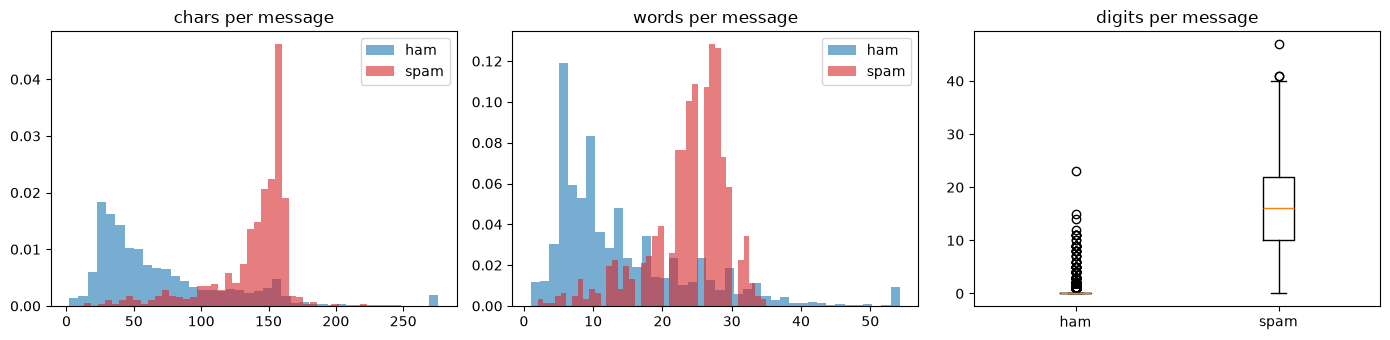

In [13]:
# length distribution by class
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, col in zip(axes[:2], ["chars", "words"]):
    for label, color in (("ham", "tab:blue"), ("spam", "tab:red")):
        ax.hist(feats.loc[raw.label == label, col].clip(upper=feats[col].quantile(0.99)),
                bins=40, alpha=0.6, density=True, label=label, color=color)
    ax.set_title(f"{col} per message")
    ax.legend()
axes[2].boxplot([feats.loc[raw.label == c, "digits"] for c in ("ham", "spam")])
axes[2].set_xticks([1, 2], ["ham", "spam"])
axes[2].set_title("digits per message")
plt.tight_layout()

label,ham,spam
5+ digit number,6.215e-04,0.783
currency symbol,3.936e-03,0.344
url,4.143e-04,0.142
uppercase share > 30%,2.548e-02,0.027
exclamation mark,1.164e-01,0.490
word 'free',1.222e-02,0.228
word 'txt' / 'text',1.637e-02,0.329


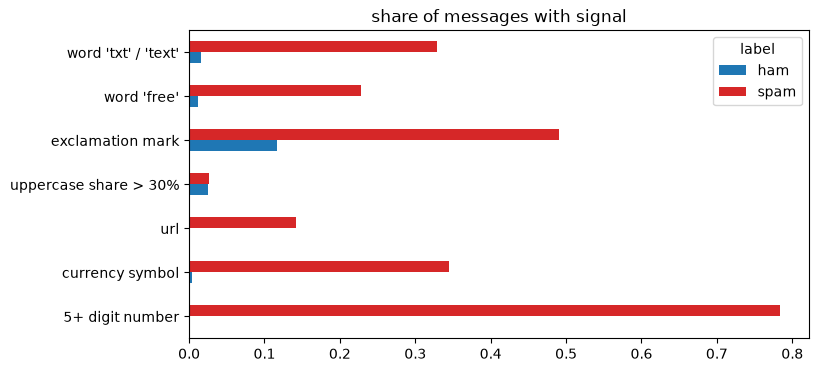

In [14]:
# share of messages with each signal
signals = pd.DataFrame({
    "5+ digit number": feats["5+ digit number"] > 0,
    "currency symbol": feats["currency symbols"] > 0,
    "url": feats["url"] > 0,
    "uppercase share > 30%": feats["uppercase share"] > 0.3,
    "exclamation mark": feats["exclamation marks"] > 0,
    "word 'free'": raw.text.str.contains(r"\bfree\b", case=False),
    "word 'txt' / 'text'": raw.text.str.contains(r"\b(?:txt|text)\b", case=False),
}).groupby(raw.label).mean().T
signals.plot.barh(figsize=(8, 4), color=["tab:blue", "tab:red"], title="share of messages with signal")
signals

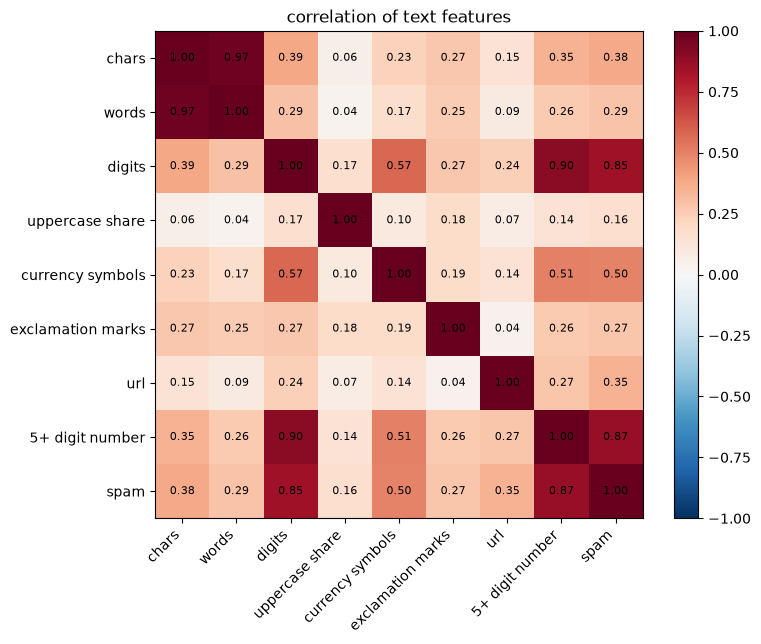

In [15]:
# feature correlation
corr = feats.assign(spam=(raw.label == "spam").astype(int)).corr()
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)), corr.columns)
for (i, j), v in np.ndenumerate(corr.to_numpy()):
    ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im)
ax.set_title("correlation of text features")
plt.tight_layout()

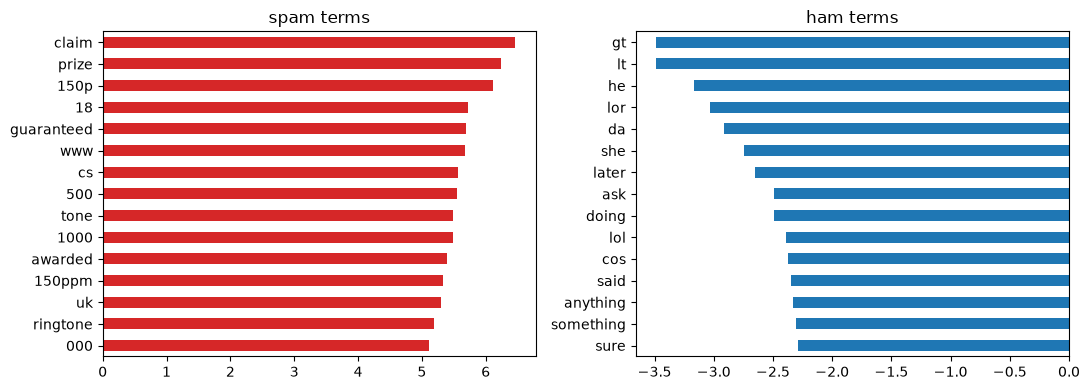

In [16]:
# top terms per class (log-odds)
vec = CountVectorizer(binary=True, min_df=5)
counts = vec.fit_transform(uniq.text)
spam = (uniq.label == "spam").to_numpy()
odds = (np.log((counts[spam].sum(0).A1 + 1) / (spam.sum() + 2))
        - np.log((counts[~spam].sum(0).A1 + 1) / ((~spam).sum() + 2)))
terms = pd.Series(odds, index=vec.get_feature_names_out()).sort_values()
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
terms.tail(15).plot.barh(ax=axes[0], color="tab:red", title="spam terms")
terms.head(15).iloc[::-1].plot.barh(ax=axes[1], color="tab:blue", title="ham terms")
plt.tight_layout()

#### Data Preprocessing

In [17]:
# grouped stratified split
train, test = data.split(uniq)
pd.DataFrame({"train": train.label.value_counts(), "test": test.label.value_counts()}).T.assign(
    spam_share=lambda d: d.spam / (d.ham + d.spam),
    shared_template_groups=len(set(train.group) & set(test.group)),
)

label,ham,spam,spam_share,shared_template_groups
train,3614,522,0.126,0
test,904,131,0.127,0


In [18]:
# leaky split vs grouped split
cols = ["pr_auc", "precision", "recall", "f1", "ham_blocked_rate"]
pd.DataFrame(report["cv"]["leakage"]).T[cols]

,pr_auc,precision,recall,f1,ham_blocked_rate
random_split_with_duplicates,0.990,0.968,0.970,0.969,0.005
group_split_deduplicated,0.988,0.965,0.964,0.965,0.005


#### Baseline Model: Logistic Regression

In [19]:
# floor: always-ham and keyword rule
X, y, g = train.text.tolist(), (train.label == "spam").astype(int).to_numpy(), train.group.to_numpy()
cv5 = StratifiedGroupKFold(5, shuffle=True, random_state=SEED)
pd.DataFrame({
    "always ham": ev.metrics(y, np.zeros_like(y)),
    "keyword rule": ev.metrics(y, ev.keyword_rule(X)),
}).T[["precision", "recall", "f1", "accuracy"]]

,precision,recall,f1,accuracy
always ham,0.000,0.000,0.000,0.874
keyword rule,0.725,0.906,0.806,0.945


In [20]:
# logistic regression, train vs validation
fit = cross_validate(ml.build("logreg"), X, y, groups=g, cv=cv5, n_jobs=-1, return_train_score=True,
                     scoring={"pr_auc": "average_precision", "f1": "f1", "recall": "recall", "precision": "precision"})
fit_table = pd.DataFrame({
    "train": {m: fit[f"train_{m}"].mean() for m in ("pr_auc", "precision", "recall", "f1")},
    "validation": {m: fit[f"test_{m}"].mean() for m in ("pr_auc", "precision", "recall", "f1")},
    "validation std": {m: fit[f"test_{m}"].std() for m in ("pr_auc", "precision", "recall", "f1")},
})
fit_table.assign(gap=fit_table.train - fit_table.validation)

,train,validation,validation std,gap
pr_auc,1.0,0.986,0.006,0.014
precision,1.0,0.988,0.009,0.012
recall,1.0,0.952,0.011,0.048
f1,1.0,0.970,0.004,0.030


,train F1,validation F1
C,,
0.01,0.957,0.945
0.10,0.971,0.956
1.00,0.995,0.965
10.00,1.000,0.970
100.00,1.000,0.968


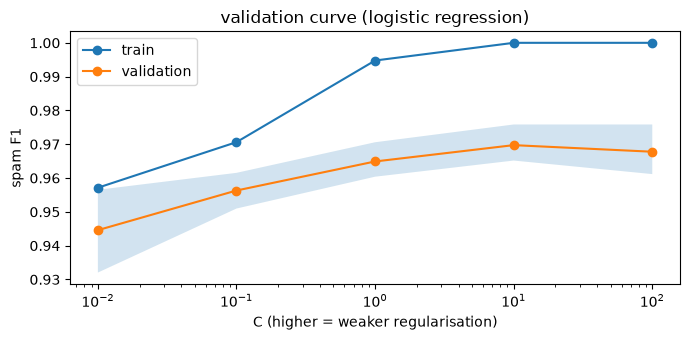

In [21]:
# validation curve over C
c_values = [0.01, 0.1, 1, 10, 100]
c_train, c_val = validation_curve(ml.build("logreg"), X, y, groups=g, cv=cv5, n_jobs=-1,
                                  param_name="logisticregression__C", param_range=c_values, scoring="f1")
plt.figure(figsize=(7, 3.5))
plt.semilogx(c_values, c_train.mean(1), "o-", label="train")
plt.semilogx(c_values, c_val.mean(1), "o-", label="validation")
plt.fill_between(c_values, c_val.min(1), c_val.max(1), alpha=0.2)
plt.xlabel("C (higher = weaker regularisation)")
plt.ylabel("spam F1")
plt.title("validation curve (logistic regression)")
plt.legend()
plt.tight_layout()
pd.DataFrame({"train F1": c_train.mean(1), "validation F1": c_val.mean(1)}, index=pd.Index(c_values, name="C"))

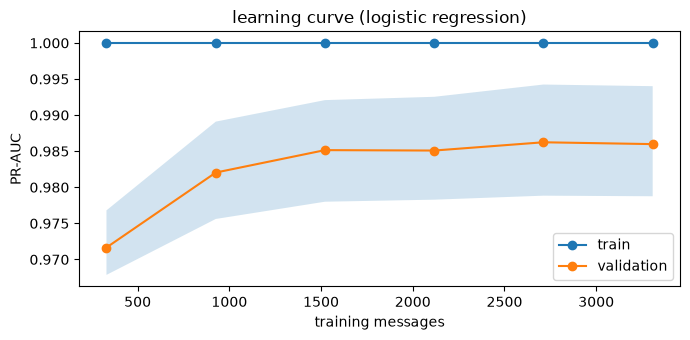

In [22]:
# learning curve, logistic regression
sizes, lc_train, lc_val = learning_curve(ml.build("logreg"), X, y, groups=g, cv=cv5, n_jobs=-1,
                                         scoring="average_precision", train_sizes=np.linspace(0.1, 1, 6))
plt.figure(figsize=(7, 3.5))
plt.plot(sizes, lc_train.mean(1), "o-", label="train")
plt.plot(sizes, lc_val.mean(1), "o-", label="validation")
plt.fill_between(sizes, lc_val.min(1), lc_val.max(1), alpha=0.2)
plt.xlabel("training messages")
plt.ylabel("PR-AUC")
plt.title("learning curve (logistic regression)")
plt.legend()
plt.tight_layout()

#### Data Modeling

In [23]:
# pipeline
model = ml.load()
print(model.pipeline)
print(len(model.pipeline[0].get_feature_names_out()), "features")

Pipeline(steps=[('featureunion',
                 FeatureUnion(transformer_list=[('word',
                                                 TfidfVectorizer(min_df=2,
                                                                 ngram_range=(1,
                                                                              2),
                                                                 sublinear_tf=True)),
                                                ('char',
                                                 TfidfVectorizer(analyzer='char_wb',
                                                                 min_df=2,
                                                                 ngram_range=(2,
                                                                              5),
                                                                 sublinear_tf=True))])),
                ('linearsvc',
                 LinearSVC(C=1, class_weight='balanced', random_state=42))])
43109 feat

In [24]:
# five models vs baseline (threshold: max 0.5% ham blocked)
models = pd.DataFrame(report["cv"]["models"]).T[cols]
models.assign(
    f1_vs_baseline=(models.f1 - models.loc["logreg", "f1"]).round(3),
    spam_caught_vs_baseline=pd.DataFrame(report["cv"]["models"]).T.tp.astype(int)
    - report["cv"]["models"]["logreg"]["tp"],
).sort_values("pr_auc", ascending=False)

,pr_auc,precision,recall,f1,ham_blocked_rate,f1_vs_baseline,spam_caught_vs_baseline
linear_svc,0.988,0.965,0.964,0.965,0.005,0.002,2
logreg,0.986,0.965,0.960,0.963,0.005,0.000,0
random_forest,0.984,0.969,0.956,0.962,0.004,-0.000,-2
complement_nb,0.979,0.965,0.950,0.958,0.005,-0.005,-5
xgboost,0.976,0.964,0.927,0.945,0.005,-0.017,-17


In [25]:
# ablation: cleaning and hand features
print("chosen:", report["cv"]["chosen"])
pd.DataFrame(report["cv"]["variants"]).T[cols]

chosen: {'model': 'linear_svc', 'variant': 'raw'}


,pr_auc,precision,recall,f1,ham_blocked_rate
raw,0.988,0.965,0.964,0.965,0.005
cleaned,0.976,0.964,0.921,0.942,0.005
raw+hand,0.986,0.965,0.964,0.965,0.005


In [26]:
# shuffled labels
pd.Series(report["cv"]["label_shuffle"]).to_frame("shuffled labels")

,shuffled labels
pr_auc,0.125
chance,0.126


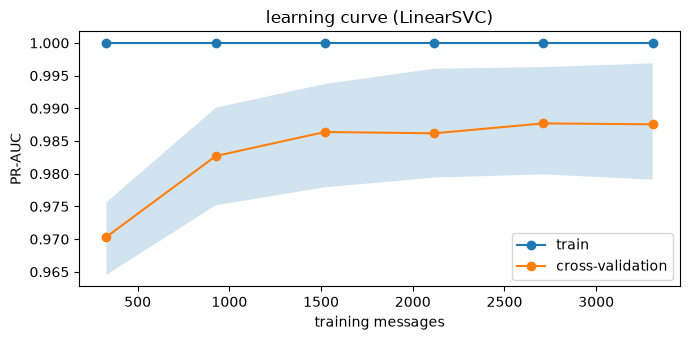

In [27]:
# learning curve, LinearSVC
sizes, fit_scores, cv_scores = learning_curve(
    ml.build("linear_svc"), X, y, groups=g, scoring="average_precision", n_jobs=-1,
    cv=cv5, train_sizes=np.linspace(0.1, 1, 6),
)
plt.figure(figsize=(7, 3.5))
plt.plot(sizes, fit_scores.mean(1), "o-", label="train")
plt.plot(sizes, cv_scores.mean(1), "o-", label="cross-validation")
plt.fill_between(sizes, cv_scores.min(1), cv_scores.max(1), alpha=0.2)
plt.xlabel("training messages")
plt.ylabel("PR-AUC")
plt.title("learning curve (LinearSVC)")
plt.legend()
plt.tight_layout()

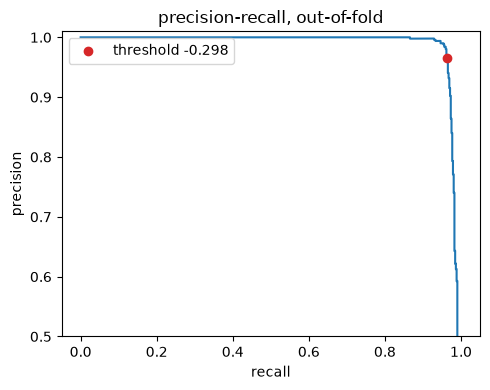

In [28]:
# precision-recall, out-of-fold
oof = ml.oof_scores(ml.build("linear_svc"), X, y, g)
precision, recall, _ = precision_recall_curve(y, oof)
chosen = oof >= model.threshold
plt.figure(figsize=(5, 4))
plt.plot(recall, precision)
plt.scatter(chosen[y == 1].mean(), y[chosen].mean(), color="tab:red", zorder=3,
            label=f"threshold {model.threshold:.3f}")
plt.xlabel("recall")
plt.ylabel("precision")
plt.ylim(0.5, 1.01)
plt.title("precision-recall, out-of-fold")
plt.legend()
plt.tight_layout()

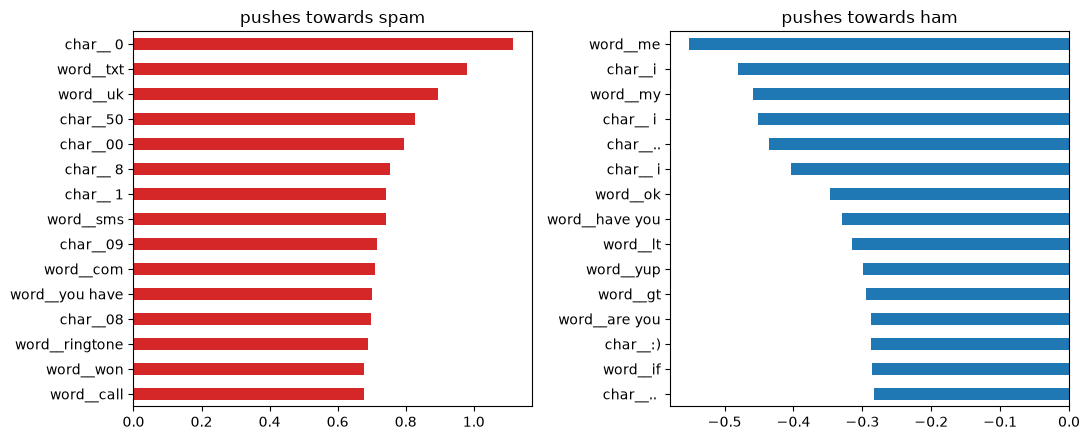

In [29]:
# top features
union, clf = model.pipeline[0], model.pipeline[-1]
weights = pd.Series(clf.coef_[0], index=union.get_feature_names_out()).sort_values()
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
weights.tail(15).plot.barh(ax=axes[0], color="tab:red", title="pushes towards spam")
weights.head(15).iloc[::-1].plot.barh(ax=axes[1], color="tab:blue", title="pushes towards ham")
plt.tight_layout()

In [30]:
# placeholder shortcut
mask = test.text.str.contains(r"&lt;[#A-Z]+&gt;")
as_is = model.predict(test.text[mask].tolist())[0]
as_digit = model.predict(test.text[mask].str.replace(r"&lt;[#A-Z]+&gt;", "0", regex=True).tolist())[0]
pd.Series({
    "test ham messages with a placeholder": mask.sum(),
    "predicted spam, placeholder kept": (as_is == "spam").sum(),
    "predicted spam, placeholder replaced by a digit": (as_digit == "spam").sum(),
    "weight of word 'lt'": weights["word__lt"],
}).to_frame("value")

,value
test ham messages with a placeholder,28.000
"predicted spam, placeholder kept",0.000
"predicted spam, placeholder replaced by a digit",3.000
weight of word 'lt',-0.314


#### LLM Classifier

In [31]:
# prompt selection on validation
print("chosen:", report["llm_prompt_selection"]["chosen"], "| n =", report["llm_prompt_selection"]["n_validation"])
pd.DataFrame(report["llm_prompt_selection"]["results"]).T[["precision", "recall", "f1", "ham_blocked_rate"]]

chosen: lender_policy_retrieved_8 | n = 300


,precision,recall,f1,ham_blocked_rate
generic_zero_shot,0.901,0.91,0.905,0.050
generic_fixed_8,0.938,0.91,0.924,0.030
generic_retrieved_8,0.941,0.96,0.950,0.030
generic_retrieved_4_per_class,0.897,0.96,0.928,0.055
lender_policy_zero_shot,0.957,0.89,0.922,0.020
lender_policy_retrieved_8,0.969,0.95,0.960,0.015


In [32]:
# retrieved examples for one message
retriever = llm.retriever()
print("pool:", len(retriever.pool), "train messages | examples per message:", retriever.k)
query = test.text.iloc[3]
print("message:", query)
pd.DataFrame(retriever(query)).iloc[::-1].head()

pool: 4136 train messages | examples per message: 8
message: XXXMobileMovieClub: To use your credit, click the WAP link in the next txt message or click here>> http://wap. xxxmobilemovieclub.com?n=QJKGIGHJJGCBL


,text,label
7,TheMob>Yo yo yo-Here comes a new selection of hot downloads for our members to get for FREE! Just click & open the n...,spam
6,Ringtone Club: Gr8 new polys direct to your mobile every week !,spam
5,Mobile Club: Choose any of the top quality items for your mobile. 7cfca1a,spam
4,Your credits have been topped up for http://www.bubbletext.com Your renewal Pin is tgxxrz,spam
3,Message Important information for O2 user. Today is your lucky day! 2 find out why log onto http://www.urawinner.com...,spam


In [33]:
# LLM versions on test
versions = json.loads((REPORTS / "llm_variants_test.json").read_text())
pd.DataFrame({k: versions[k] for k in ("generic_fixed_8", "generic_retrieved_8", "lender_policy_v1_retrieved_8",
                                    "lender_policy_v2_retrieved_8")}).T[
    ["precision", "recall", "f1", "fp", "fn"]]

,precision,recall,f1,fp,fn
generic_fixed_8,0.796,0.924,0.855,31,10
generic_retrieved_8,0.826,0.939,0.879,26,8
lender_policy_v1_retrieved_8,0.939,0.939,0.939,8,8
lender_policy_v2_retrieved_8,0.961,0.931,0.946,5,9


#### Metrics

In [34]:
# test results
ml_m, llm_m = report["metrics_ml"], report["metrics_llm"]
print("test messages:", ml_m["n"])
pd.DataFrame({
    "always ham": ml_m["baselines"]["always_ham"],
    "keyword rule": ml_m["baselines"]["keyword_rule"],
    f"ML ({ml_m['model']})": ml_m["test"],
    f"LLM ({llm_m['model']})": llm_m["test"],
}).T[["precision", "recall", "f1", "accuracy", "ham_blocked_rate"]]

test messages: 1035


,precision,recall,f1,accuracy,ham_blocked_rate
always ham,0.000,0.000,0.000,0.873,0.000
keyword rule,0.674,0.885,0.766,0.931,0.062
ML (linear_svc),0.955,0.962,0.958,0.989,0.007
LLM (gemma4:e4b),0.961,0.931,0.946,0.986,0.006


In [35]:
# bootstrap 95% CI
pd.DataFrame({
    name: {k: f"{lo:.3f} - {hi:.3f}" for k, (lo, hi) in m["ci95"].items()}
    for name, m in (("ML", ml_m), ("LLM", llm_m))
}).T

,precision,recall,f1,accuracy
ML,0.914 - 0.986,0.927 - 0.992,0.931 - 0.981,0.983 - 0.995
LLM,0.924 - 0.992,0.883 - 0.971,0.913 - 0.973,0.979 - 0.993


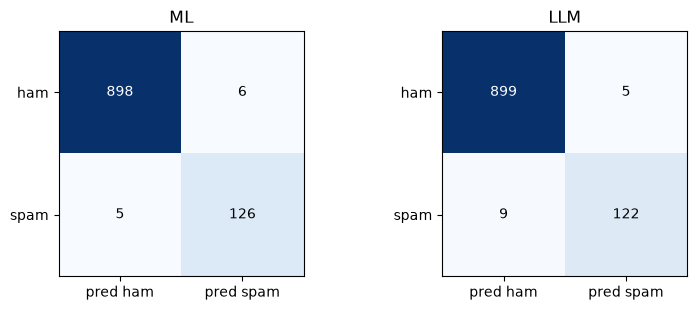

In [36]:
# confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(8, 3.2))
for ax, (name, m) in zip(axes, (("ML", ml_m["test"]), ("LLM", llm_m["test"]))):
    grid = np.array([[m["tn"], m["fp"]], [m["fn"], m["tp"]]])
    ax.imshow(grid, cmap="Blues")
    for (i, j), v in np.ndenumerate(grid):
        ax.text(j, i, v, ha="center", va="center", color="white" if v > grid.max() / 2 else "black")
    ax.set_xticks([0, 1], ["pred ham", "pred spam"])
    ax.set_yticks([0, 1], ["ham", "spam"])
    ax.set_title(name)
plt.tight_layout()

In [37]:
# McNemar, ML vs LLM
pd.Series(report["comparison"]).to_frame("ML vs LLM")

,ML vs LLM
first,ml
second,llm
only_first_correct,10
only_second_correct,7
p_value,0.629


In [38]:
# latency and reliability
pd.DataFrame({
    "ML": ml_m["latency_ms"],
    "LLM": {**llm_m["latency_ms"], "failed_calls": llm_m["failed_calls"],
            "repeat_agreement": llm_m["repeat_agreement"], "few_shot_examples": llm_m["shots"]},
}).T

,p50,p95,failed_calls,repeat_agreement,few_shot_examples
ML,4.225,6.664,NaN,NaN,NaN
LLM,329.305,491.466,0,1.0,8 retrieved


#### Error Analysis

In [39]:
# probe set (50 modern messages)
probe = report["probe"]
print("n =", probe["n"], probe["counts"])
pd.DataFrame({k: probe[k] for k in ("ml", "llm")}).T

n = 50 {'modern_phishing': 10, 'legit_transactional': 10, 'lender_notice': 10, 'loan_scam': 10, 'personal': 5, 'injection': 5}


,overall,injection,legit_transactional,lender_notice,loan_scam,modern_phishing,personal
ml,0.68,1.0,0.3,0.4,0.8,0.9,1.0
llm,0.98,1.0,1.0,1.0,1.0,0.9,1.0


In [40]:
# probe errors
p = pd.read_csv(REPORTS / "probe_predictions.csv")
wrong = p[(p.ml_pred != p.label) | (p.llm_pred != p.label)]
print(len(wrong), "of", len(p))
wrong.head()

16 of 50


,kind,label,text,ml_pred,llm_pred
3,modern_phishing,spam,"Hi Mum, I dropped my phone and this is my new number. Can you text me back on WhatsApp? I need help paying a bill today",ham,ham
10,legit_transactional,ham,Your verification code is 482913. It expires in 10 minutes. Do not share this code with anyone.,spam,ham
11,legit_transactional,ham,Reminder: your loan repayment of $215.40 is due on 24 Nov. No action is needed if your direct debit is set up.,spam,ham
12,legit_transactional,ham,"Your payment of $215.40 has been received. Thank you. Your remaining balance is $3,104.60.",spam,ham
13,legit_transactional,ham,"Hi Sam, your appointment with Dr Lee is confirmed for Tue 25 Nov at 9:30am. Reply YES to confirm or call 02 5550 000...",spam,ham


In [41]:
# test errors
errors = pd.read_csv(REPORTS / "errors.csv")
print(len(errors), "of", ml_m["n"])
errors[["label", "ml_pred", "llm_pred", "text"]].head()

21 of 1035


,label,ml_pred,llm_pred,text
0,ham,spam,ham,Are you free now?can i call now?
1,ham,ham,spam,So there's a ring that comes with the guys costumes. It's there so they can gift their future yowifes. Hint hint
2,ham,ham,spam,"&lt;#&gt; %of pple marry with their lovers... becz they hav gud undrstndng dat avoids problems. i sent dis 2 u, u wi..."
3,spam,ham,spam,"Hi ya babe x u 4goten bout me?' scammers getting smart..Though this is a regular vodafone no, if you respond you get..."
4,ham,spam,spam,Dont you have message offer


#### Takeaway

1. Data: 5,574 messages, 13.4% spam. 403 duplicates and their templates are removed before the split, so no test message has a near-copy in train.
2. Signals: spam is longer (median 149 vs 52 characters) and carries long numbers, currency and "call / txt / free". `&lt;#&gt;` placeholders only occur in ham and the ML model leans on them.
3. Baseline: logistic regression already reaches F1 0.97 in CV with a small train/validation gap. The other four models do not beat it by more than noise.
4. ML (LinearSVC): test F1 0.958, 6 of 904 real messages blocked, 4 ms per message.
5. LLM (Gemma 4, lender policy + 8 retrieved examples): test F1 0.946, 5 of 904 blocked, about 330 ms per message. Not significantly different from ML here (p = 0.63).
6. Modern messages: LLM 49/50, ML 34/50. The ML model blocks most real lender and transactional SMS. In production: ML first, LLM for uncertain cases, and labelled in-domain data before either goes live.
